# GLOF — data understanding

### Importing necessary libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Importing the dataset

In [4]:
glof = pd.read_csv("../build_ml_GLOF.csv")
glof.head()

,lake_id,year,lake_area_km2,elevation_m,perimeter_km,area_uncertainty_km2,expansion_rate_km2yr,lake_volume_1e6_m3,dam_height_m,shape_index,area_change_km2,pct_of_critical_area,yrs_to_critical_area,expansion_accel_km2yr2,dam_stability_index,peak_discharge_m3s
0,GLO_80.85718_29.91975,2024,0.004988,4782.9,0.36469,0.003,0.0,0.0609,15.00,1.4567,0.000000,1.00,500.0,0.000000,0.0367,121.69
1,GLO_80.87763_30.04078,2017,0.055611,4448.8,1.25819,0.010,0.0,1.1127,15.99,1.5051,0.000000,11.12,500.0,0.000000,0.0657,722.82
2,GLO_80.87763_30.04078,2018,0.052037,4448.8,1.23996,0.010,0.0,1.0261,15.83,1.5334,-0.003574,10.41,500.0,0.000000,0.0660,684.41
3,GLO_80.87763_30.04078,2019,0.055860,4448.8,1.27643,0.010,0.0,1.1188,16.00,1.5235,0.000249,11.17,500.0,0.007398,0.0968,725.49
4,GLO_80.87763_30.04078,2020,0.054780,4448.8,1.22172,0.010,0.0,1.0925,15.95,1.4725,-0.000831,10.96,500.0,-0.004904,0.0824,713.93


### Project Charter

In [5]:
## business understanding and charter
print("decision: which lakes get a watch because they hit critical area within 50 years")
print("owner: DHM / NDRRMA hydrologist")
print("target: glof_within_50yr (from yrs_to_critical_area)")
print("one row: one lake in one year")
print("baseline: always say no, and a simple expansion rule")
print("watch out: pct_of_critical_area is just area / 0.005")
print("watch out: most yrs_to_critical_area values are capped at 500")


decision: which lakes get a watch because they hit critical area within 50 years
owner: DHM / NDRRMA hydrologist
target: glof_within_50yr (from yrs_to_critical_area)
one row: one lake in one year
baseline: always say no, and a simple expansion rule
watch out: pct_of_critical_area is just area / 0.005
watch out: most yrs_to_critical_area values are capped at 500


### At a Glance!

In [6]:
print(glof.shape)

(11904, 16)


In [7]:
glof.columns

Index(['lake_id', 'year', 'lake_area_km2', 'elevation_m', 'perimeter_km',
       'area_uncertainty_km2', 'expansion_rate_km2yr', 'lake_volume_1e6_m3',
       'dam_height_m', 'shape_index', 'area_change_km2',
       'pct_of_critical_area', 'yrs_to_critical_area',
       'expansion_accel_km2yr2', 'dam_stability_index', 'peak_discharge_m3s'],
      dtype='object')

In [8]:
glof.dtypes

lake_id                    object
year                        int64
lake_area_km2             float64
elevation_m               float64
perimeter_km              float64
area_uncertainty_km2      float64
expansion_rate_km2yr      float64
lake_volume_1e6_m3        float64
dam_height_m              float64
shape_index               float64
area_change_km2           float64
pct_of_critical_area      float64
yrs_to_critical_area      float64
expansion_accel_km2yr2    float64
dam_stability_index       float64
peak_discharge_m3s        float64
dtype: object

In [9]:
glof.isnull().sum()

lake_id                   0
year                      0
lake_area_km2             0
elevation_m               0
perimeter_km              0
area_uncertainty_km2      0
expansion_rate_km2yr      0
lake_volume_1e6_m3        0
dam_height_m              0
shape_index               0
area_change_km2           0
pct_of_critical_area      0
yrs_to_critical_area      0
expansion_accel_km2yr2    0
dam_stability_index       0
peak_discharge_m3s        0
dtype: int64

### No missing values in our dataset

In [10]:
summary = pd.DataFrame(
    {
        "dtype": glof.dtypes,
        "missing_%": glof.isna().mean() * 100,
        "unique": glof.nunique(),
    }
)
print(summary)

                          dtype  missing_%  unique
lake_id                  object        0.0    2329
year                      int64        0.0       8
lake_area_km2           float64        0.0    2866
elevation_m             float64        0.0    2129
perimeter_km            float64        0.0     565
area_uncertainty_km2    float64        0.0      69
expansion_rate_km2yr    float64        0.0     107
lake_volume_1e6_m3      float64        0.0    6930
dam_height_m            float64        0.0     978
shape_index             float64        0.0    3888
area_change_km2         float64        0.0    1121
pct_of_critical_area    float64        0.0    2374
yrs_to_critical_area    float64        0.0    1041
expansion_accel_km2yr2  float64        0.0    1472
dam_stability_index     float64        0.0    2084
peak_discharge_m3s      float64        0.0   10672


### Identifying Duplicates

In [11]:
print(f"Duplicated Rows: {glof.duplicated().sum()}")
print(f"Duplicated lake_id+year: {glof.duplicated(['lake_id', 'year']).sum()}")
print(f"unique lakes: {glof['lake_id'].nunique()}")

Duplicated Rows: 0
Duplicated lake_id+year: 0
unique lakes: 2329


### No duplicates in our dataset, alongside checking for same entries in the same year

In [12]:
glof.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
year,11904.0,2020.539,2.345,2017.000,2019.000,2020.000,2023.000,2024.000
lake_area_km2,11904.0,0.047,0.148,0.001,0.007,0.016,0.036,3.598
elevation_m,11904.0,4898.689,441.296,1973.200,4614.400,4930.100,5199.900,7381.200
perimeter_km,11904.0,0.934,1.010,0.146,0.437,0.638,1.055,15.572
area_uncertainty_km2,11904.0,0.007,0.007,0.001,0.003,0.005,0.008,0.097
expansion_rate_km2yr,11904.0,0.000,0.004,-0.037,-0.000,0.000,0.000,0.082
lake_volume_1e6_m3,11904.0,1.316,6.665,0.008,0.097,0.249,0.702,189.363
dam_height_m,11904.0,16.448,2.397,15.000,15.000,15.000,17.193,33.660
shape_index,11904.0,1.527,0.213,1.165,1.399,1.472,1.584,4.203
area_change_km2,11904.0,0.001,0.018,-0.416,-0.001,0.000,0.001,0.591


                        mean    median  max
Peak discharge (m³/s)	630.455	290.800	38,556.090

### average peak discharge is approximately 630 m³/s, while the median is approximately 291 m³/s.
### difference is seemingly large
### because a relatively small number of observations have extremely high discharge values.
### this suggests that your target variable has a right-skewed distribution.
### in simple terms, most observations have relatively low discharge values, while a smaller number have very high values.

### Checking if there are impossible values

In [13]:
print("area <= 0:", (glof["lake_area_km2"] <= 0).sum())
print("volume <= 0:", (glof["lake_volume_1e6_m3"] <= 0).sum())
print("discharge <= 0:", (glof["peak_discharge_m3s"] <= 0).sum())
# print("dam_height == 15:", (glof["dam_height_m"] == 15).mean())
# print("neg expansion:", (glof["expansion_rate_km2yr"] < 0).sum())
# print("neg area_change:", (glof["area_change_km2"] < 0).sum())

area <= 0: 0
volume <= 0: 0
discharge <= 0: 0


In [14]:
print(glof["year"].value_counts().sort_index())
print()
print(glof.groupby("lake_id").size().describe())

year
2017    1559
2018    1411
2019    1437
2020    1613
2021    1403
2022    1260
2023    1453
2024    1768
Name: count, dtype: int64

count    2329.000000
mean        5.111207
std         2.847212
min         1.000000
25%         2.000000
50%         6.000000
75%         8.000000
max         8.000000
dtype: float64


#### this suggests multiple lakes are observed in multiple years
#### not every lake is observed every year

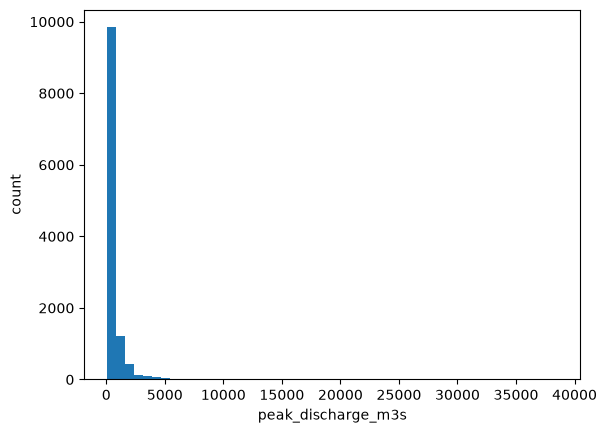

In [15]:
plt.hist(glof["peak_discharge_m3s"], bins=50)
plt.xlabel("peak_discharge_m3s")
plt.ylabel("count")
plt.show()

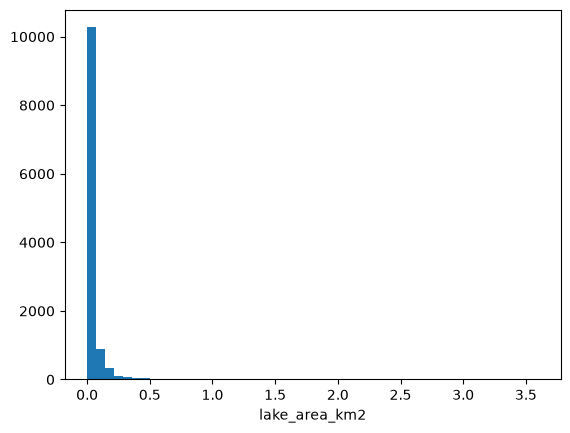

In [16]:
plt.hist(glof["lake_area_km2"], bins=50)
plt.xlabel("lake_area_km2")
plt.show()

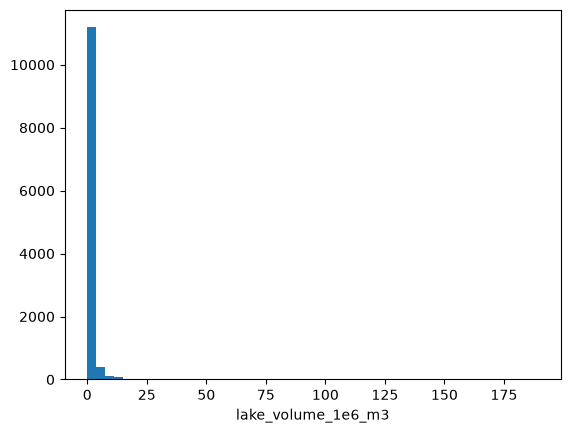

In [17]:
plt.hist(glof["lake_volume_1e6_m3"], bins=50)
plt.xlabel("lake_volume_1e6_m3")
plt.show()

#### most observations are concentrated at relatively low values, with a long tail towards larger discharge values.

### Identifying Data Leakage

In [18]:
glof.select_dtypes(include="number").corr()["peak_discharge_m3s"].sort_values(ascending=False)

peak_discharge_m3s        1.000000
pct_of_critical_area      0.985424
lake_area_km2             0.985423
lake_volume_1e6_m3        0.972730
perimeter_km              0.863577
area_uncertainty_km2      0.861117
dam_stability_index       0.745162
dam_height_m              0.658245
expansion_rate_km2yr      0.645092
area_change_km2           0.492073
shape_index               0.318858
expansion_accel_km2yr2    0.040286
year                      0.000627
elevation_m              -0.025733
yrs_to_critical_area     -0.470561
Name: peak_discharge_m3s, dtype: float64

#### correlation isn't causation
#### there are strong correlation among obvious physical traits

#### let's see if they have a recognizable patterns


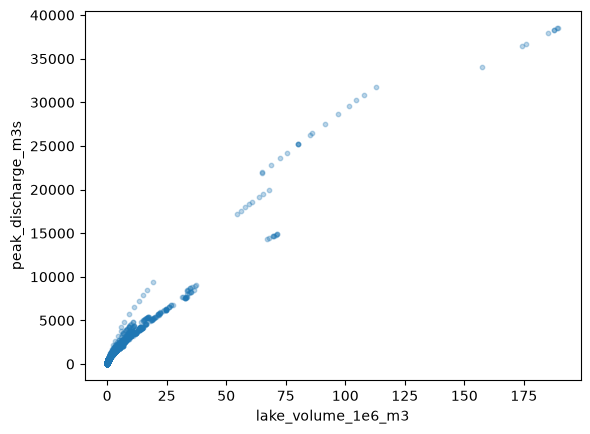

In [19]:
plt.scatter(glof["lake_volume_1e6_m3"], glof["peak_discharge_m3s"], s=10, alpha=0.3)
plt.xlabel("lake_volume_1e6_m3")
plt.ylabel("peak_discharge_m3s")
plt.show()

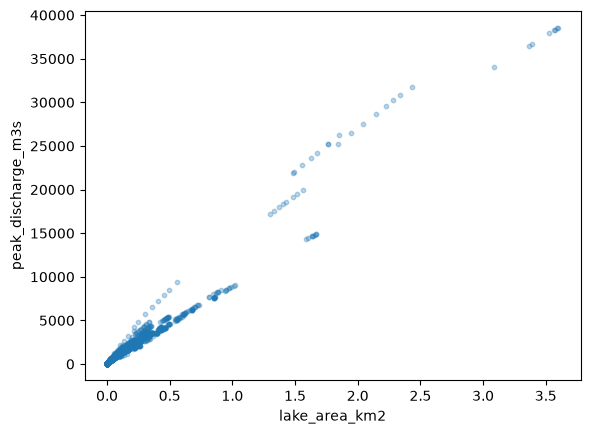

In [20]:
plt.scatter(glof["lake_area_km2"], glof["peak_discharge_m3s"], s=10, alpha=0.3)
plt.xlabel("lake_area_km2")
plt.ylabel("peak_discharge_m3s")
plt.show()

#### as there are huge differences in measurement size, the above scatter plot doesn't give us significant idea
#### however, as we take log it compresses the scale
#### also it can help us debunk if there's power-law relation that defn causes a leakage

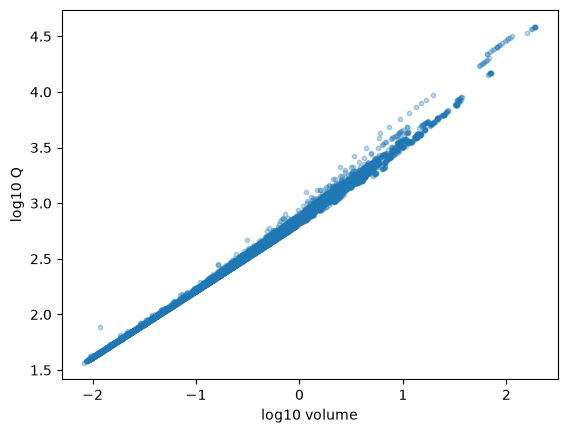

In [21]:
plt.scatter(np.log10(glof["lake_volume_1e6_m3"]), np.log10(glof["peak_discharge_m3s"]), s=10, alpha=0.3)
plt.xlabel("log10 volume")
plt.ylabel("log10 Q")
plt.show()

#### this shows a very strong pattern between volume and the discharge

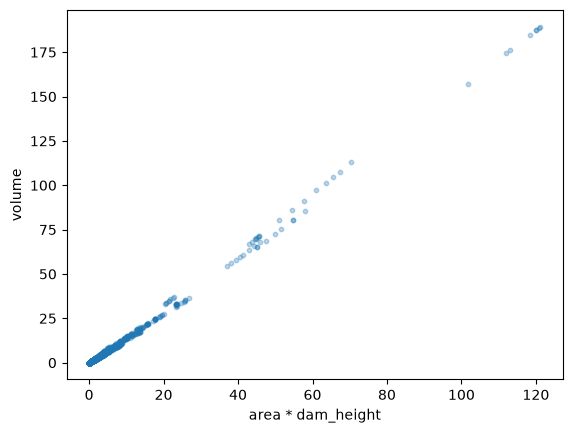

In [22]:
plt.scatter(glof["lake_area_km2"] * glof["dam_height_m"], glof["lake_volume_1e6_m3"], s=10, alpha=0.3)
plt.xlabel("area * dam_height")
plt.ylabel("volume")
plt.show()

#### since there are physical quantities, two features can sometime describe the same thing

In [23]:
print("corr volume vs area:", glof["lake_volume_1e6_m3"].corr(glof["lake_area_km2"]))
print("corr volume vs area*dam:", glof["lake_volume_1e6_m3"].corr(glof["lake_area_km2"] * glof["dam_height_m"]))

corr volume vs area: 0.9827816744638238
corr volume vs area*dam: 0.998180816647605


#### lake volume and lake area have an extremely strong positive correlation.
#### volume and area are proportional quantity that makes sense
#### however, this is a sign of multi-collinearity 

#### the term area * dam is the volume we manually calculated
#### correlation between our calculated volume and observation are nearly the same
#### this means there's leakage through formula

In [24]:
V = glof["lake_volume_1e6_m3"].to_numpy()
Q = glof["peak_discharge_m3s"].to_numpy()
H = glof["dam_height_m"].to_numpy()

X = np.column_stack([np.log(V), np.ones(len(V))])
coef, *_ = np.linalg.lstsq(X, np.log(Q), rcond=None)
pred = np.exp(coef[1]) * V ** coef[0]
print(f"Q ≈ {np.exp(coef[1]):.2f} * V^{coef[0]:.3f}")
print("mae:", np.mean(np.abs(Q - pred)))
print("r2:", 1 - ((Q - pred) ** 2).sum() / ((Q - Q.mean()) ** 2).sum())

X2 = np.column_stack([np.log(V), np.log(H), np.ones(len(V))])
coef2, *_ = np.linalg.lstsq(X2, np.log(Q), rcond=None)
pred2 = np.exp(coef2[2]) * V ** coef2[0] * H ** coef2[1]
print(f"Q ≈ {np.exp(coef2[2]):.2f} * V^{coef2[0]:.3f} * H^{coef2[1]:.3f}")
print("mae:", np.mean(np.abs(Q - pred2)))
print("r2:", 1 - ((Q - pred2) ** 2).sum() / ((Q - Q.mean()) ** 2).sum())

Q ≈ 734.42 * V^0.645
mae: 70.65455173677792
r2: 0.8247269857082841
Q ≈ 102.64 * V^0.602 * H^0.685
mae: 46.272427981022965
r2: 0.8934717323852659


#### peak discharge can also be calculated using volume
#### as we fit a mathematical model, we get a R2 score of 0.82. this means the volume part of data explains around 80% of variability in peak discharge

#### again as we also include dam height in our model, the R2 increases to 0.89, meaning 90% of variation is again explained in peak discharge

#### this suggest potential leakage in the target variable

In [25]:
first = glof.sort_values(["lake_id", "year"]).groupby("lake_id").head(1)
print("first year area_change == 0:", (first["area_change_km2"] == 0).mean())

first year area_change == 0: 1.0


### New target: when the lake hits critical area

In [26]:
print(glof.columns.tolist())

glof[[
    "pct_of_critical_area",
    "yrs_to_critical_area",
    "expansion_accel_km2yr2",
    "dam_stability_index"
]].describe().T

['lake_id', 'year', 'lake_area_km2', 'elevation_m', 'perimeter_km', 'area_uncertainty_km2', 'expansion_rate_km2yr', 'lake_volume_1e6_m3', 'dam_height_m', 'shape_index', 'area_change_km2', 'pct_of_critical_area', 'yrs_to_critical_area', 'expansion_accel_km2yr2', 'dam_stability_index', 'peak_discharge_m3s']


,count,mean,std,min,25%,50%,75%,max
pct_of_critical_area,11904.0,9.456322,29.681033,0.220000,1.430000,3.1400,7.300000,719.650000
yrs_to_critical_area,11904.0,472.597726,98.107650,-100.040000,500.000000,500.0000,500.000000,500.000000
expansion_accel_km2yr2,11904.0,0.000369,0.018772,-0.484041,-0.001247,0.0000,0.001413,0.834083
dam_stability_index,11904.0,0.079018,0.073283,0.013000,0.042000,0.0555,0.085700,0.800400


#### notice that `yrs_to_critical_area` maximum is exactly 500, and even its median is 500. This suggests that many observations are not given an actual estimated time beyond that point. Instead, their values are capped at 500.

In [27]:
print("yrs == 500 (capped):", (glof["yrs_to_critical_area"] == 500).mean())
print("yrs < 0 (already past):", (glof["yrs_to_critical_area"] < 0).mean())
print("yrs < 50:", (glof["yrs_to_critical_area"] < 50).mean())
print("pct >= 1 (already at/above critical):", (glof["pct_of_critical_area"] >= 1).mean())

yrs == 500 (capped): 0.90625
yrs < 0 (already past): 0.008904569892473119
yrs < 50: 0.019069220430107527
pct >= 1 (already at/above critical): 0.8230006720430108


#### 90.625% of observations have a capped value of 500.

#### This means we cannot reliably treat yrs_to_critical_area as an ordinary regression target. The model would mostly learn to predict the artificial cap rather than a meaningful number of years.

#### we classify instead: does the lake hit critical area within 50 years?


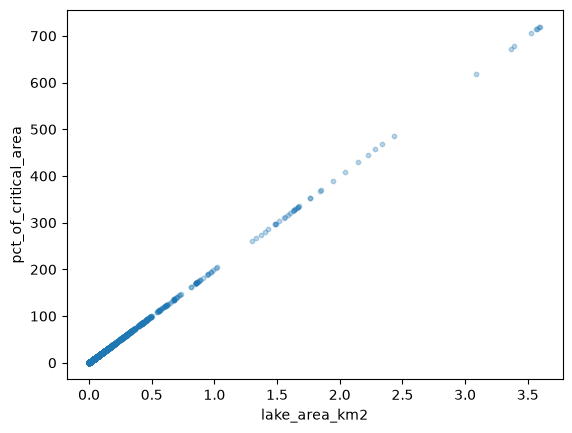

corr area vs pct: 0.9999999952374073


In [28]:
plt.scatter(glof["lake_area_km2"], glof["pct_of_critical_area"], s=10, alpha=0.3)
plt.xlabel("lake_area_km2")
plt.ylabel("pct_of_critical_area")
plt.show()
print("corr area vs pct:", glof["lake_area_km2"].corr(glof["pct_of_critical_area"]))

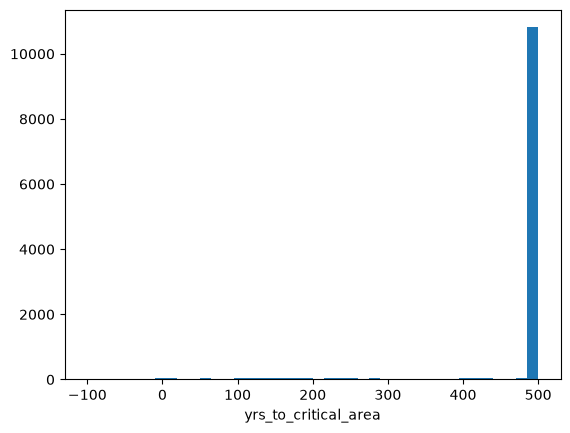

In [29]:
plt.hist(glof["yrs_to_critical_area"], bins=40)
plt.xlabel("yrs_to_critical_area")
plt.show()

### Cleaning for the new target

#### since most lakes are capped at 500, this won't get a useful resul
#### instead we will convert them into a classification problem rather than simply a regression problem

#### • If yrs_to_critical_area is less than 50:  label the lake 1 (Yes — Danger).
#### • If it is 50 or more (including all those 500s):  label the lake 0 (No — Safe for now).

In [30]:
# - sort so later lags / group splits are honest
# - flag the 500 cap and already-past years
# - label: hit critical area within 50 years (includes already past)

glof = glof.sort_values(["lake_id", "year"]).reset_index(drop=True)
glof["yrs_capped"] = (glof["yrs_to_critical_area"] == 500).astype(int)
glof["already_past_critical"] = (glof["yrs_to_critical_area"] < 0).astype(int)
glof["glof_within_50yr"] = (glof["yrs_to_critical_area"] < 50).astype(int)
print(glof["glof_within_50yr"].value_counts())
print("positive share:", glof["glof_within_50yr"].mean())

glof_within_50yr
0    11677
1      227
Name: count, dtype: int64
positive share: 0.019069220430107527


#### HIghly imbalanced data

In [31]:
print("missing:", glof.isna().sum().sum())
print("rows:", len(glof))
glof.head()

missing: 0
rows: 11904


,lake_id,year,lake_area_km2,elevation_m,perimeter_km,area_uncertainty_km2,expansion_rate_km2yr,lake_volume_1e6_m3,dam_height_m,shape_index,area_change_km2,pct_of_critical_area,yrs_to_critical_area,expansion_accel_km2yr2,dam_stability_index,peak_discharge_m3s,yrs_capped,already_past_critical,glof_within_50yr
0,GLO_80.85718_29.91975,2024,0.004988,4782.9,0.36469,0.003,0.0,0.0609,15.00,1.4567,0.000000,1.00,500.0,0.000000,0.0367,121.69,1,0,0
1,GLO_80.87763_30.04078,2017,0.055611,4448.8,1.25819,0.010,0.0,1.1127,15.99,1.5051,0.000000,11.12,500.0,0.000000,0.0657,722.82,1,0,0
2,GLO_80.87763_30.04078,2018,0.052037,4448.8,1.23996,0.010,0.0,1.0261,15.83,1.5334,-0.003574,10.41,500.0,0.000000,0.0660,684.41,1,0,0
3,GLO_80.87763_30.04078,2019,0.055860,4448.8,1.27643,0.010,0.0,1.1188,16.00,1.5235,0.000249,11.17,500.0,0.007398,0.0968,725.49,1,0,0
4,GLO_80.87763_30.04078,2020,0.054780,4448.8,1.22172,0.010,0.0,1.0925,15.95,1.4725,-0.000831,10.96,500.0,-0.004904,0.0824,713.93,1,0,0


In [32]:
glof.to_csv("glof_clean.csv", index=False)
print(glof.shape)

(11904, 19)
